# CartPole-v1: policy gradient, with and without a baseline
Algorithms and validation live in `cartpole.py` and `validate.py`. This notebook reads saved logs and generates the required plots without training or importing PyTorch.

The primary seed, 1668, was specified before the full experiments. All final checkpoints were evaluated with stochastic actions over 500 fresh episodes. Two additional seeds show training variability. Both methods use 8,000 training episodes, gamma 0.95 and Adam learning rate 0.01. All experiments ran on CPU with **zero GPUs**.

The training objective uses discounted rewards; the assignment's plotted episode scores are **undiscounted** reward sums, with a maximum of 500. The learned baseline reduces measured gradient variance at a fixed initial policy, but gives lower final evaluation scores in these training runs.

In [1]:
from pathlib import Path
import json
import csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
ROOT = Path.cwd()
if not (ROOT / 'cartpole.py').exists():
    ROOT = ROOT / 'mlds_assignment1_cartpole'
FIG = ROOT / 'results/figures'
FIG.mkdir(parents=True, exist_ok=True)
SEEDS = (1668,1669,1670)
MODES = ('no_baseline','baseline')
labels = {'no_baseline':'Basic REINFORCE', 'baseline':'REINFORCE with baseline'}
colors = {'no_baseline':'#2563eb','baseline':'#0f766e'}
logs = {(m,s): np.genfromtxt(ROOT / f'runs/{m}_seed{s}/training.csv',delimiter=',',names=True,dtype=None,encoding='utf-8') for m in MODES for s in SEEDS}
evals = {(m,s): json.loads((ROOT / f'runs/{m}_seed{s}/evaluation.json').read_text()) for m in MODES for s in SEEDS}
validation = json.loads((ROOT/'validation/validation.json').read_text())
plt.rcParams.update({'font.size':10.5,'figure.figsize':(6.8,3.2),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.18,'pdf.fonttype':42})
def save(fig,name):
    fig.tight_layout()
    for ext in ('png','pdf'):
        fig.savefig(FIG/f'{name}.{ext}',dpi=170,bbox_inches='tight')
    plt.show()
def moving_average(y):
    return np.convolve(y,np.ones(100)/100,mode='valid')
def learning_curve(mode):
    data=logs[mode,1668]
    rewards=data['reward']
    fig,ax=plt.subplots()
    ax.plot(data['episode'],rewards,color=colors[mode],alpha=.22,lw=.65,label='Episode reward')
    ax.plot(data['episode'][99:],moving_average(rewards),color=colors[mode],lw=2,label='100-episode moving average')
    ax.set(xlabel='Training episode',ylabel='Undiscounted episode reward',ylim=(0,510),title=labels[mode]+' — seed 1668')
    ax.legend()
    save(fig,f'{mode}_training')
def histogram(mode):
    scores=np.loadtxt(ROOT/f'runs/{mode}_seed1668/evaluation_rewards.csv',skiprows=1)
    stats=evals[mode,1668]
    fig,ax=plt.subplots()
    ax.hist(scores,bins=np.linspace(0,500,26),color=colors[mode],edgecolor='white')
    ax.axvline(stats['mean'],color='black',ls='--',label=f"Mean {stats['mean']:.2f}; SD {stats['population_std']:.2f}")
    ax.set(xlabel='Undiscounted episode reward',ylabel='Number of evaluation episodes',xlim=(0,510),title=labels[mode]+' — 500 evaluation episodes')
    ax.legend()
    save(fig,f'{mode}_evaluation_histogram')


## Part 1(a): basic policy gradient
The policy is a 4–64–2 neural network with tanh hidden activation and categorical actions. One Adam update follows every 32 complete episodes. Reward-to-go is used without subtracting a baseline or normalizing returns. The loss retains the outer gamma-to-the-time factor for the discounted episodic objective. A fixed scale of 0.05 and gradient-norm clipping at 10 are applied to both methods.

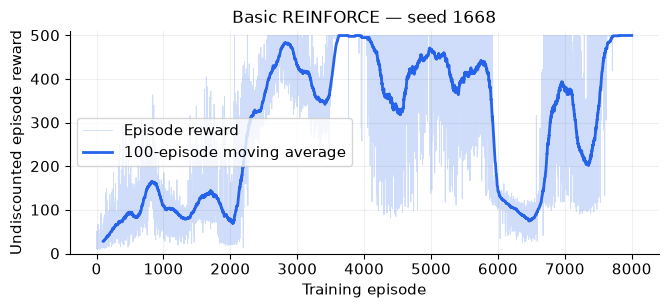

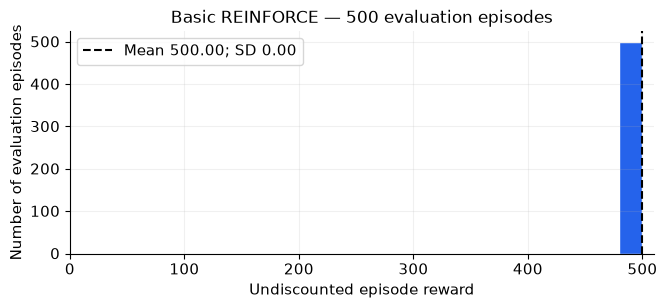

In [2]:
learning_curve('no_baseline')
histogram('no_baseline')

## Part 2, CartPole: learned baseline
A second 5–64–1 network predicts discounted reward-to-go from the four state components plus elapsed time divided by 500. The baseline is evaluated before its update, detached from the actor loss, and does not depend on the sampled action. After each actor update it receives five MSE/Adam updates at learning rate 0.01. Full Monte Carlo returns are used; this is REINFORCE with a baseline, without temporal-difference bootstrapping.

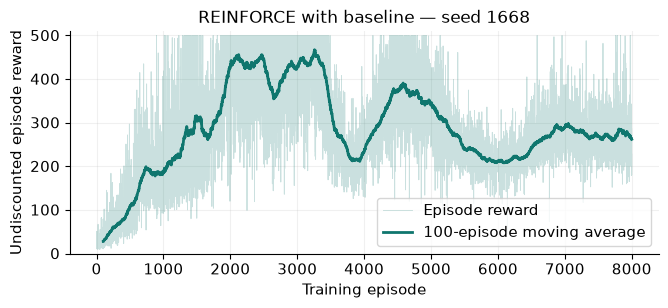

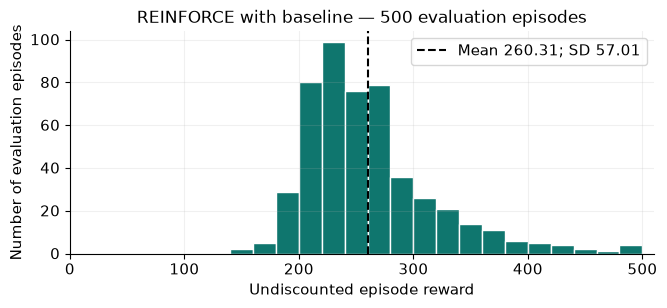

In [3]:
learning_curve('baseline')
histogram('baseline')

## All three seeds: performance and variability
Primary-seed performance alone is insufficient to establish robustness. Both algorithms use the final checkpoint after 8,000 episodes. No checkpoint is selected using evaluation performance. The same 500 evaluation reset seeds are used across all methods and training seeds. Standard deviations below describe variation among episodes for each fixed trained model.

| Method | Training seed | Evaluation episodes | Mean reward | Population SD | Fraction reaching 500 |
|---|---:|---:|---:|---:|---:|
| Basic REINFORCE | 1668 | 500 | 500.000 | 0.000 | 1.000 |
| Basic REINFORCE | 1669 | 500 | 271.824 | 28.856 | 0.000 |
| Basic REINFORCE | 1670 | 500 | 483.886 | 65.298 | 0.928 |
| REINFORCE with baseline | 1668 | 500 | 260.308 | 57.013 | 0.008 |
| REINFORCE with baseline | 1669 | 500 | 360.516 | 79.141 | 0.100 |
| REINFORCE with baseline | 1670 | 500 | 349.940 | 76.321 | 0.092 |

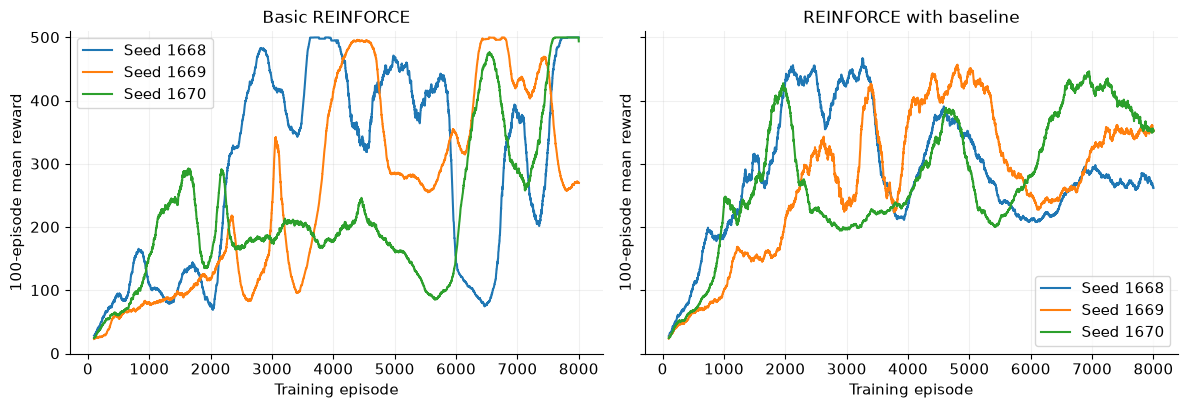

Basic REINFORCE: mean of seed means 418.570, sample SD across three seed means 127.341
REINFORCE with baseline: mean of seed means 323.588, sample SD across three seed means 55.057
Uniform random reference: {'passed': None, 'episodes': 500, 'mean': 22.782, 'std': 12.057797311283684, 'mean_discounted_return': 12.854140281677246}


In [4]:
rows=['| Method | Training seed | Evaluation episodes | Mean reward | Population SD | Fraction reaching 500 |', '|---|---:|---:|---:|---:|---:|']
for mode in MODES:
    for seed in SEEDS:
        v=evals[mode,seed]
        rows.append(f"| {labels[mode]} | {seed} | {v['episodes']} | {v['mean']:.3f} | {v['population_std']:.3f} | {v['fraction_500']:.3f} |")
display(Markdown('\n'.join(rows)))
fig,axes=plt.subplots(1,2,figsize=(12,4.2),sharey=True)
for ax,mode in zip(axes,MODES):
    for seed in SEEDS:
        d=logs[mode,seed]
        ax.plot(d['episode'][99:],moving_average(d['reward']),label=f'Seed {seed}')
    ax.set(xlabel='Training episode',ylabel='100-episode mean reward',title=labels[mode],ylim=(0,510))
    ax.legend()
save(fig,'three_seed_learning_comparison')
for mode in MODES:
    means=np.array([evals[mode,s]['mean'] for s in SEEDS])
    print(f'{labels[mode]}: mean of seed means {means.mean():.3f}, sample SD across three seed means {means.std(ddof=1):.3f}')
print('Uniform random reference:',validation['uniform_random_reference'])


## Isolated baseline variance experiment
Freeze one initial policy. Fit a baseline on 512 independent episodes, then compute both gradient estimators on the same 512 held-out trajectories. Summing the sample variances across policy parameters gives the trace of the gradient covariance matrix. This isolates a baseline's statistical effect from the changes in policy that occur during training.

The observed reduction is about 84%. It does **not** imply that a learned baseline must produce a better final policy: the baseline training runs above scored lower. Only three training seeds were tested.

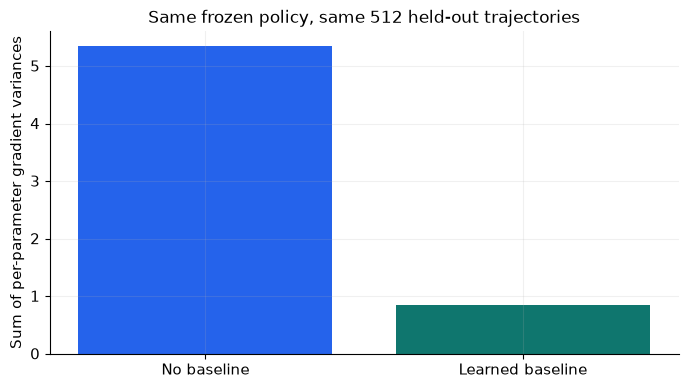

{
  "passed": null,
  "trajectories": 512,
  "fitting_trajectories": 512,
  "variance_no_baseline": 5.33826208114624,
  "variance_baseline": 0.8424209952354431,
  "variance_ratio": 0.15780809979538454,
  "variance_reduction_fraction": 0.8421919002046154,
  "mean_gradient_difference_norm": 0.04739914461970329,
  "rms_standard_error_of_mean_difference": 0.11760218441486359,
  "baseline_mse": 10.523124694824219,
  "explanation": "Trace of sample gradient covariance (sum of per-parameter variances). A fixed policy and paired held-out paths isolate baseline effects from policy learning. Measured reduction is evidence, not a universal guarantee."
}


In [5]:
v=validation['frozen_policy_gradient_variance']
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(['No baseline','Learned baseline'],[v['variance_no_baseline'],v['variance_baseline']],color=[colors[m] for m in MODES])
ax.set(ylabel='Sum of per-parameter gradient variances',title='Same frozen policy, same 512 held-out trajectories')
save(fig,'frozen_policy_gradient_variance')
print(json.dumps(v,indent=2))


## Validation and a ten-decision trace
The validation script tests hand-computed returns, an exactly enumerable policy-gradient example, the direction of a rewarded-action update, environment reproducibility, physical termination, and time-limit truncation. The trace exposes the complete four-component state, right-action probability, sampled action, and reward. A high probability does not force that action because the policy remains stochastic.

These are reproducible computational checks. The independent investigation for your own report can use this trace to calculate or predict a few steps and examine whether the policy's decisions make sense.

In [6]:
rows=['| Experiment | Passed |','|---|---|']
for name,entry in validation.items():
    if entry.get('passed') is not None:
        rows.append(f"| {name.replace('_',' ')} | {entry['passed']} |")
display(Markdown('\n'.join(rows)))
with (ROOT/'validation/first_ten_steps.csv').open() as f:
    trace=list(csv.DictReader(f))
rows=['| t | Position | Velocity | Angle | Angular velocity | P(right) | Action | Reward |','|---:|---:|---:|---:|---:|---:|---:|---:|']
for r in trace:
    rows.append(f"| {r['t']} | {float(r['position']):.4f} | {float(r['velocity']):.4f} | {float(r['angle']):.4f} | {float(r['angular_velocity']):.4f} | {float(r['p_right']):.4f} | {r['action']} | {r['reward']} |")
display(Markdown('\n'.join(rows)))


| Experiment | Passed |
|---|---|
| analytic discounted returns | True |
| zero discount is immediate reward | True |
| enumerated policy gradient and baseline invariance | True |
| rewarded action probability increases | True |
| seeded environment replay | True |
| cart position boundary | True |
| pole angle boundary | True |
| time limit is truncation | True |

| t | Position | Velocity | Angle | Angular velocity | P(right) | Action | Reward |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 0.0128 | -0.0119 | -0.0466 | -0.0308 | 0.1019 | 0 | 1.0 |
| 1 | 0.0125 | -0.2063 | -0.0472 | 0.2469 | 0.8335 | 1 | 1.0 |
| 2 | 0.0084 | -0.0105 | -0.0423 | -0.0603 | 0.0700 | 0 | 1.0 |
| 3 | 0.0082 | -0.2050 | -0.0435 | 0.2187 | 0.7711 | 0 | 1.0 |
| 4 | 0.0041 | -0.3995 | -0.0391 | 0.4974 | 0.9930 | 1 | 1.0 |
| 5 | -0.0039 | -0.2039 | -0.0292 | 0.1926 | 0.7348 | 1 | 1.0 |
| 6 | -0.0080 | -0.0083 | -0.0253 | -0.1091 | 0.0428 | 0 | 1.0 |
| 7 | -0.0082 | -0.2031 | -0.0275 | 0.1755 | 0.6828 | 1 | 1.0 |
| 8 | -0.0122 | -0.0076 | -0.0240 | -0.1257 | 0.0337 | 0 | 1.0 |
| 9 | -0.0124 | -0.2023 | -0.0265 | 0.1593 | 0.6266 | 0 | 1.0 |

## Limitations and next experiments
The primary no-baseline model achieved 500 in every evaluation episode, but other seeds did not. A lower-variance estimator did not guarantee better evaluation scores. Also, with gamma 0.95, long episode discounted returns approach 20, even when their undiscounted scores differ substantially. For a trajectory of length T and reward +1 per step, the discounted return is `(1 - 0.95**T)/0.05`.

Further experiments should use more training seeds, independent tuning/evaluation seeds, learning-rate and batch-size sweeps, critic-fitting ablations, gradient-variance measurements at several policy checkpoints, and stress tests under changed initial states or physics. See `CARTPOLE_REPORT.tex` / PDF for the full discussion.